In [1]:
# import sympy
from sympy import (symbols, expand, Rational, init_printing, sqrt, cos, sin,
                   init_printing, pprint, simplify, factor, trigsimp, collect,
                   cancel, powsimp, expand_power_exp, powdenest)
init_printing()

x, y, z = symbols("x y z")

expr = x + 2*y
e2 = 3*x + y**2
e3 = expr*e2*z
e4 = expand(e3)
# # print(e3)
# e4
# print((cos(x)+2).subs(cos(x), 3))


In [2]:
"""Calculations for m^-"""
x_0, y_0, theta0, x_c, y_c, r_c, rho, x_f, y_f, q = symbols(
    "x_0, y_0, theta0, x_c, y_c, r_c, rho, x_f, y_f, q")

R = r_c + rho
# print(R)

c_0x = x_0 - rho*sin(theta0)
c_0y = y_0 + rho*cos(theta0)

cos1 = (1 - q**2)/(1 + q**2)
sin1 = 2*q/(1 + q**2)

c_1x = x_c - R*sin1
c_1y = y_c + R*cos1

m_minus_x = c_1x - c_0x
m_minus_x = collect(factor(m_minus_x), q)
m_minus_y = c_1y - c_0y
m_minus_y = collect(factor(m_minus_y),q)
# print("m_minus_x =", m_minus_x)
# print("m_minus_y =", m_minus_y)

m_d_minus = factor(m_minus_x**2 + m_minus_y**2)
m_d_minus = collect(m_d_minus, q)

# Simplify m_d_minus by regrouping some constant terms into subterms
m_d_minus_numer, m_d_minus_denom = m_d_minus.as_numer_denom()
# m_d_minus_numer
# m_d_minus_denom
# m_d_minus == m_d_minus_numer/m_d_minus_denom
c_mdm2, c_mdm1, c_mdm0 = symbols("c_mdm2, c_mdm1, c_mdm0")
c_md_min2 = m_d_minus_numer.coeff(q,2)
c_md_min1 = m_d_minus_numer.coeff(q,1)
c_md_min0 = m_d_minus_numer.coeff(q,0)
m_d_minus_numer = m_d_minus_numer - c_md_min2*q**2 - c_md_min1*q - c_md_min0 + c_mdm2*q**2 + c_mdm1*q + c_mdm0
# m_d_minus_numer
# c_md_min2
m_d_minus = m_d_minus_numer/m_d_minus_denom
# m_d_minus

# m_d_minus
# m_minus_x
# m_minus_y

# print(c_md_min2)
# print(c_md_min1)
# print(c_md_min0)

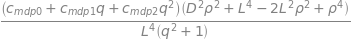

In [3]:
"""Calculations for m^+"""

# sin_thet, cos_thet, sin_delt, cos_delt = symbols("sin_thet, cos_thet, sin_delt, cos_delt")
L = sqrt( (c_1x - x_f)**2 + (c_1y - y_f)**2 )
L = expand(L)
L = symbols("L")
D = sqrt(L**2 - rho**2)
D = symbols('D')

sin_thet = D/L
# print(sin_thet)
cos_thet = rho/L
sin_delt = (y_f - c_1y)/L
# sin_delt = expand(sin_delt)
cos_delt = (x_f - c_1x)/L

x_R = c_1x + rho*(cos_delt*cos_thet + sin_delt*sin_thet)
y_R = c_1y + rho*(sin_delt*cos_thet - cos_delt*sin_thet)

m_plus_x = x_f - x_R
m_plus_x = factor(m_plus_x)
m_plus_x = collect(m_plus_x, [D, L])
m_plus_y = y_f - y_R
m_plus_y = factor(m_plus_y)
m_plus_y = collect(m_plus_y, [D, L])

m_d_plus = m_plus_x**2 + m_plus_y**2
m_d_plus = factor(m_d_plus)
m_d_plus = collect(m_d_plus, q)

# Simplify m_d_plus by regrouping some constant terms into subterms
m_d_plus_numer, m_d_plus_denom = m_d_plus.as_numer_denom()
# m_d_plus_numer
# m_d_plus_denom
m_d_plus_coeff = D**2*rho**2 + L**4 - 2*L**2*rho**2 + rho**4
m_d_plus_numer_simpl = m_d_plus_numer/m_d_plus_coeff
m_d_plus_numer_simpl
c_mdp2, c_mdp1, c_mdp0 = symbols("c_mdp2, c_mdp1, c_mdp0")
c_md_plus2 = m_d_plus_numer_simpl.coeff(q,2)
c_md_plus1 = m_d_plus_numer_simpl.coeff(q,1)
c_md_plus0 = m_d_plus_numer_simpl.coeff(q,0)
# c_md_plus2
# c_md_plus1
# c_md_plus0
substitutions = dict(zip([c_md_plus2, c_md_plus1, c_md_plus0], [c_mdp2, c_mdp1, c_mdp0]))
m_d_plus_numer = m_d_plus_numer.subs(substitutions)
m_d_plus = m_d_plus_numer/m_d_plus_denom
# m_d_plus

# m_plus_x
# m_plus_y
m_d_plus

# print(c_md_plus2)
# print(c_md_plus1)
# print(c_md_plus0)

In [4]:
"""Prepare the Ls and Ds before substituting them in the formula"""

# Manage L**2, denom = (q**2 + 1)
L_2 = factor((c_1x - x_f)**2 + (c_1y - y_f)**2)
L_2 = collect(L_2, q)
L_2_numer, L_2_denom = L_2.as_numer_denom()
c_L20, c_L21, c_L22 = symbols("c_L20, c_L21, c_L22")
c_L20_t = L_2_numer.coeff(q, 0)
c_L21_t = L_2_numer.coeff(q, 1)
c_L22_t = L_2_numer.coeff(q, 2)
substitutions_3 = dict(zip([c_L20_t, c_L21_t, c_L22_t], [c_L20, c_L21, c_L22]))
L_2_numer = L_2_numer.subs(substitutions_3)
L_2 = L_2_numer/L_2_denom

# Manage L**4, denom = (q**2 + 1)**2
L_4 = factor(expand(L_2**2))
L_4_numer, L_4_denom = L_4.as_numer_denom()
L_4_numer = collect(expand(L_4_numer), q)
# L_4_denom = expand(L_4_denom)
L_4 = L_4_numer/L_4_denom

# Manage L**6, denom = (q**2 + 1)**3
L_6 = factor(expand(L_2**3))
L_6_numer, L_6_denom = L_6.as_numer_denom()
L_6_numer = collect(expand(L_6_numer), q)
L_6 = L_6_numer/L_6_denom

# Manage L**8, denom = (q**2 + 1)**4
L_8 = factor(expand(L_2**4))
L_8_numer, L_8_denom = L_8.as_numer_denom()
L_8_numer = collect(expand(L_8_numer), q)
L_8 = L_8_numer/L_8_denom

# Manage D**2, denom = (q**2 + 1)
D_2 = L_2 - rho**2
D_2_numer, D_2_denom = D_2.as_numer_denom()
D_2_numer = collect(expand(D_2_numer), q)
D_2 = D_2_numer/D_2_denom
# D_2 = factor((L_2 - rho**2)*(q**2+1))

# Manage D**4, denom = (q**2 + 1)**2
D_4 = factor(expand(D_2**2))
D_4_numer, D_4_denom = D_4.as_numer_denom()
D_4_numer = collect(expand(D_4_numer), q)
D_4 = D_4_numer/D_4_denom

# L_2
# L_2_numer
# L_2_denom
# L_4
# L_6
# L_8
# L_4_numer
# L_4_denom
# D_2
# D_2_numer
# D_2_denom
# D_4

# print(c_L20_t)
# print(c_L21_t)
# print(c_L22_t)

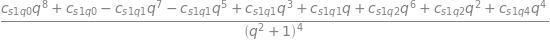

In [23]:
"""Combining m^- and m^+, first side of eq 37"""

v_tx = cos1
v_ty = sin1

side1 = (v_tx*m_minus_x + v_ty*m_minus_y)**2
side1_numer, side1_denom = side1.as_numer_denom()
side1_numer = collect(expand(side1_numer), q)
c_s1_q0, c_s1_q1, c_s1_q2, c_s1_q4 = symbols(
    "c_s1_q0, c_s1_q1, c_s1_q2, c_s1_q4")
c_s1_q0t = side1_numer.coeff(q,0)
c_s1_q1t = side1_numer.coeff(q,1)
c_s1_q2t = side1_numer.coeff(q,2)
c_s1_q4t = side1_numer.coeff(q,4)
subs = dict(zip([c_s1_q0t, c_s1_q1t, c_s1_q2t, c_s1_q4t],
                [c_s1_q0, c_s1_q1, c_s1_q2, c_s1_q4]))
side1_numer = side1_numer.subs(subs)

side1 = side1_numer/side1_denom

# side1_numer
# side1_denom
side1

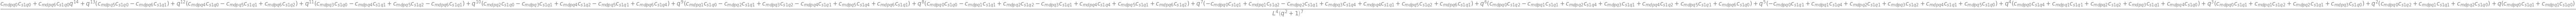

In [50]:
### Get the whole left side of eq 38

m_d_plus_num, m_d_plus_den = m_d_plus.as_numer_denom()
# m_d_plus_rep = m_d_plus.
m_d_plus_num = m_d_plus_num.xreplace({D**2: D_2, L**2: L_2, L**4: L_4})
m_d_plus_num = factor(m_d_plus_num, q)
m_d_plus_num_num, m_d_plus_num_den = m_d_plus_num.as_numer_denom()
m_d_plus_num_num = collect(expand(m_d_plus_num_num), q)

(c_mdp_q0,
c_mdp_q1,
c_mdp_q2,
c_mdp_q3,
c_mdp_q4,
c_mdp_q5,
c_mdp_q6) = symbols(
    "c_mdp_q0, c_mdp_q1, c_mdp_q2, c_mdp_q3, c_mdp_q4, c_mdp_q5, c_mdp_q6")
c_mdp_q0t = m_d_plus_num_num.coeff(q,0)
c_mdp_q1t = m_d_plus_num_num.coeff(q,1)
c_mdp_q2t = m_d_plus_num_num.coeff(q,2)
c_mdp_q3t = m_d_plus_num_num.coeff(q,3)
c_mdp_q4t = m_d_plus_num_num.coeff(q,4)
c_mdp_q5t = m_d_plus_num_num.coeff(q,5)
c_mdp_q6t = m_d_plus_num_num.coeff(q,6)
subs = dict(zip([c_mdp_q0t, c_mdp_q1t, c_mdp_q2t, c_mdp_q3t, c_mdp_q4t, c_mdp_q5t, c_mdp_q6t],
                [c_mdp_q0, c_mdp_q1, c_mdp_q2, c_mdp_q3, c_mdp_q4, c_mdp_q5, c_mdp_q6]))
m_d_plus_num_num = m_d_plus_num_num.subs(subs)


m_d_plus_num = m_d_plus_num_num/m_d_plus_num_den


m_d_plus_rep = m_d_plus_num/m_d_plus_den # NOW USE m_d_plus_rep INSTEAD OF M_D_PLUS

all_side1 = side1*m_d_plus_rep
all_side1_numer, all_side1_denom = all_side1.as_numer_denom()

# all_side1_numer = all_side1_numer.xreplace({D**2: D_2, L**2: L_2, L**4: L_4})
# all_side1_numer = collect(expand(all_side1_numer), q)
# all_side1_numer_num, all_side1_numer_den = all_side1_numer.as_numer_denom()

all_side1_numer = collect(expand(all_side1_numer), q)

all_side1 = all_side1_numer/all_side1_denom # denom L**4*(q**2 + 1)**7

# m_d_plus_rep
# m_d_plus_num
# m_d_plus_num_num
all_side1
# all_side1_numer
# all_side1_denom
# all_side1_numer_den
# all_side1_numer_num

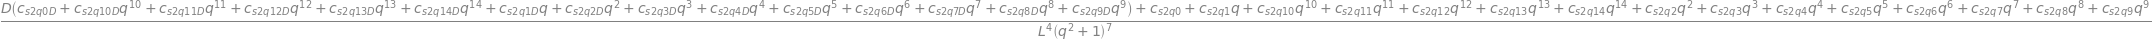

In [75]:
"""Combining m^- and m^+, second side of eq 37"""

side2 = (v_tx*m_plus_x + v_ty*m_plus_y)**2
side2_numer, side2_denom = side2.as_numer_denom()
side2_numer = collect(expand(side2_numer), [D,L,q])

side2_numer = side2_numer.xreplace({D**2: D_2, L**2: L_2, L**4: L_4})
side2_numer_num, side2_numer_den = side2_numer.as_numer_denom()
side2_numer_num = collect(expand(side2_numer_num),[D,q]) # degree 14

# Assemble coefficients that are NOT mulitplied by D
(c_s2_q0,
c_s2_q1,
c_s2_q2,
c_s2_q3,
c_s2_q4,
c_s2_q5,
c_s2_q6,
c_s2_q7,
c_s2_q8,
c_s2_q9,
c_s2_q10,
c_s2_q11,
c_s2_q12,
c_s2_q13,
c_s2_q14) = symbols(
    "c_s2_q0, c_s2_q1, c_s2_q2, c_s2_q3, c_s2_q4, c_s2_q5, c_s2_q6, c_s2_q7, c_s2_q8, c_s2_q9, c_s2_q10, c_s2_q11, c_s2_q12, c_s2_q13, c_s2_q14")
c_s2_q0t = side2_numer_num.coeff(q,0)
c_s2_q1t = side2_numer_num.coeff(q,1)
c_s2_q2t = side2_numer_num.coeff(q,2)
c_s2_q3t = side2_numer_num.coeff(q,3)
c_s2_q4t = side2_numer_num.coeff(q,4)
c_s2_q5t = side2_numer_num.coeff(q,5)
c_s2_q6t = side2_numer_num.coeff(q,6)
c_s2_q7t = side2_numer_num.coeff(q,7)
c_s2_q8t = side2_numer_num.coeff(q,8)
c_s2_q9t = side2_numer_num.coeff(q,9)
c_s2_q10t = side2_numer_num.coeff(q,10)
c_s2_q11t = side2_numer_num.coeff(q,11)
c_s2_q12t = side2_numer_num.coeff(q,12)
c_s2_q13t = side2_numer_num.coeff(q,13)
c_s2_q14t = side2_numer_num.coeff(q,14)
subs = dict(zip([c_s2_q0t, c_s2_q1t, c_s2_q2t, c_s2_q3t, c_s2_q4t, c_s2_q5t, c_s2_q6t, c_s2_q7t, c_s2_q8t, c_s2_q9t, c_s2_q10t, c_s2_q11t, c_s2_q12t, c_s2_q13t, c_s2_q14t],
                [c_s2_q0, c_s2_q1, c_s2_q2, c_s2_q3, c_s2_q4, c_s2_q5, c_s2_q6, c_s2_q7, c_s2_q8, c_s2_q9, c_s2_q10, c_s2_q11, c_s2_q12, c_s2_q13, c_s2_q14]))
side2_numer_num = side2_numer_num.subs(subs)

# Assemble coefficients that are mulitplied by D
D_term = collect(side2_numer_num.coeff(D,1), q)
(c_s2_q0D,
c_s2_q1D,
c_s2_q2D,
c_s2_q3D,
c_s2_q4D,
c_s2_q5D,
c_s2_q6D,
c_s2_q7D,
c_s2_q8D,
c_s2_q9D,
c_s2_q10D,
c_s2_q11D,
c_s2_q12D,
c_s2_q13D,
c_s2_q14D) = symbols(
    "c_s2_q0D, c_s2_q1D, c_s2_q2D, c_s2_q3D, c_s2_q4D, c_s2_q5D, c_s2_q6D, c_s2_q7D, c_s2_q8D, c_s2_q9D, c_s2_q10D, c_s2_q11D, c_s2_q12D, c_s2_q13D, c_s2_q14D")
c_s2_q0Dt = D_term.coeff(q,0)
c_s2_q1Dt = D_term.coeff(q,1)
c_s2_q2Dt = D_term.coeff(q,2)
c_s2_q3Dt = D_term.coeff(q,3)
c_s2_q4Dt = D_term.coeff(q,4)
c_s2_q5Dt = D_term.coeff(q,5)
c_s2_q6Dt = D_term.coeff(q,6)
c_s2_q7Dt = D_term.coeff(q,7)
c_s2_q8Dt = D_term.coeff(q,8)
c_s2_q9Dt = D_term.coeff(q,9)
c_s2_q10Dt = D_term.coeff(q,10)
c_s2_q11Dt = D_term.coeff(q,11)
c_s2_q12Dt = D_term.coeff(q,12)
c_s2_q13Dt = D_term.coeff(q,13)
c_s2_q14Dt = D_term.coeff(q,14)
subs = dict(zip([c_s2_q0Dt, c_s2_q1Dt, c_s2_q2Dt, c_s2_q3Dt, c_s2_q4Dt, c_s2_q5Dt, c_s2_q6Dt, c_s2_q7Dt, c_s2_q8Dt, c_s2_q9Dt, c_s2_q10Dt, c_s2_q11Dt, c_s2_q12Dt, c_s2_q13Dt, c_s2_q14Dt],
                [c_s2_q0D, c_s2_q1D, c_s2_q2D, c_s2_q3D, c_s2_q4D, c_s2_q5D, c_s2_q6D, c_s2_q7D, c_s2_q8D, c_s2_q9D, c_s2_q10D, c_s2_q11D, c_s2_q12D, c_s2_q13D, c_s2_q14D]))
D_term = D_term.subs(subs)

side2_numer_num = side2_numer_num - D*side2_numer_num.coeff(D,1) + D*D_term
side2_numer = side2_numer_num/side2_numer_den


side2 = side2_numer/side2_denom
# side2_denom

side2
# side2_numer
# side2_numer_num
# D_term
# side2_numer_den
# all_side2_numer
# m_d_minus
# all_side2_denom

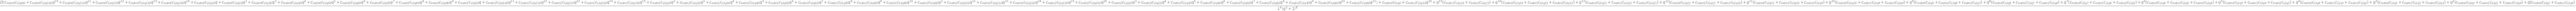

In [83]:
### Get whole side 2

all_side2 = side2*m_d_minus
all_side2_numer, all_side2_denom = all_side2.as_numer_denom()

all_side2_numer = collect(expand(all_side2_numer), [D,q])

all_side2 = all_side2_numer/all_side2_denom

all_side2 # denom L**4*(q**2 + 1)**8
# all_side2_numer
# all_side2_denom

In [90]:
### Simplify denominators

all_side1_num, all_side1_den = all_side1.as_numer_denom()
all_side2_num, all_side2_den = all_side2.as_numer_denom()

all_side1_simpl = all_side1_num*(q**2 + 1)
all_side1_simpl = collect(expand(all_side1_simpl),q)
all_side2_simpl = all_side2_num

all_side1_simpl
# all_side2_simpl
# all_side1_num
# all_side2_num
# all_side1 # denom L**4*(q**2 + 1)**7
# all_side2 # denom L**4*(q**2 + 1)**8

In [94]:
### Combine both sides

D_term_all = all_side2_simpl.coeff(D,1)

all_no_D = all_side1_simpl - all_side2_simpl + D_term_all*D
all_no_D = collect(all_no_D, q)

all_no_D
# D_term_all

In [97]:
### Squard D_term

D_term_all_2 = D**2*D_term_all**2
D_term_all_2 = collect(expand(D_term_all_2),[D,q])


D_term_all_2

In [ ]:
# """Combine everything together"""

# all_combined = comb_noD_rep - D_term_rep
# all_combined = collect(all_combined, q)

# # all_combined

In [ ]:
# """Extract all the needed terms"""

# T0 = all_combined.coeff(q,0)
# T1 = all_combined.coeff(q,1)
# T2 = all_combined.coeff(q,2)
# T3 = all_combined.coeff(q,3)
# T4 = all_combined.coeff(q,4)
# T5 = all_combined.coeff(q,5)
# T6 = all_combined.coeff(q,6)
# T7 = all_combined.coeff(q,7)
# T8 = all_combined.coeff(q,8)
# T9 = all_combined.coeff(q,9)
# T10 = all_combined.coeff(q,10)
# T11 = all_combined.coeff(q,11)
# T12 = all_combined.coeff(q,12)
# T13 = all_combined.coeff(q,13)
# T14 = all_combined.coeff(q,14)
# T15 = all_combined.coeff(q,15)
# T16 = all_combined.coeff(q,16)
# T17 = all_combined.coeff(q,17)
# T18 = all_combined.coeff(q,18)
# T19 = all_combined.coeff(q,19)
# T20 = all_combined.coeff(q,20)
# T21 = all_combined.coeff(q,21)
# T22 = all_combined.coeff(q,22)
# T23 = all_combined.coeff(q,23)
# T24 = all_combined.coeff(q,24)
# T25 = all_combined.coeff(q,25)
# T26 = all_combined.coeff(q,26)
# T27 = all_combined.coeff(q,27)
# T28 = all_combined.coeff(q,28)
# # T29 = all_combined.coeff(q,29)
# # Max is 28!

# # print(T0)
# # print(T1)
# # print(T2)
# # print(T3)
# # print(T4)
# # print(T5)
# # print(T6)
# # print(T7)
# # print(T8)
# # print(T9)
# # print(T10)
# # print(T11)
# # print(T12)
# # print(T13)
# # print(T14)
# # print(T15)
# # print(T16)
# # print(T17)
# # print(T18)
# # print(T19)
# # print(T20)
# # print(T21)
# # print(T22)
# # print(T23)
# # print(T24)
# # print(T25)
# # print(T26)
# # print(T27)
# # print(T28)
# # print(T29) # Nope! This term is empty, max is 28!